*Previous notebook: none, this is the start of the path. — This notebook: the perceptron (village-fair example) and the AND function built from scratch with a single neuron.*

# Neural Networks: An Introduction

A **neural network** is a computational model loosely inspired by biological neurons in the brain. It consists of layers of interconnected nodes called **neurons**, which pass weighted signals to each other to produce an output.

## The Building Block: The Perceptron

The simplest artificial neuron is the **perceptron**. It takes $n$ binary inputs $x_1, x_2, \ldots, x_n \in \{0, 1\}$ and produces a single binary output.

Each input is multiplied by a **weight** $w_i \in \mathbb{R}$, which encodes how important that input is. The neuron computes the **weighted sum**:

$$z = \sum_{i=1}^{n} w_i x_i = w_1 x_1 + w_2 x_2 + \cdots + w_n x_n$$

and fires based on a **threshold** $\theta$:

$$\text{output} = \begin{cases} 0 & \text{if } z \leq \theta \\\ 1 & \text{if } z > \theta \end{cases}$$

It is common to replace $\theta$ with a **bias** $b = -\theta$, giving an equivalent and more convenient form:

$$\text{output} = \begin{cases} 0 & \text{if } \mathbf{w} \cdot \mathbf{x} + b \leq 0 \\\ 1 & \text{if } \mathbf{w} \cdot \mathbf{x} + b > 0 \end{cases}$$

where $\mathbf{w} \cdot \mathbf{x} = \sum_i w_i x_i$ is the dot product of weights and inputs. A large positive bias $b$ makes the neuron fire easily; a very negative $b$ makes it rarely fire.


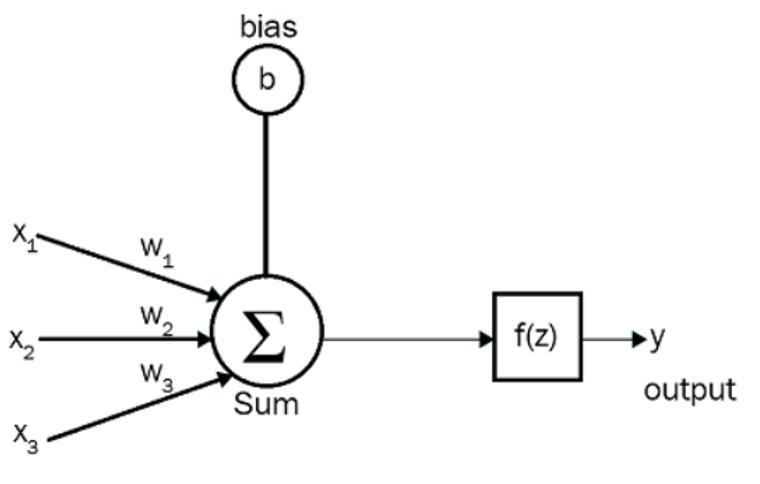

## Example: Should I Go to the Village Fair?
*(Adapted from M. Nielsen, "Neural Networks and Deep Learning")*

You want to decide whether to attend the local fair. Your decision depends on three factors:

| Input | Variable | Meaning |
|:-----:|:--------:|:--------|
| $x_1$ | Weather  | Is the weather good? (1 = yes, 0 = no) |
| $x_2$ | Buses    | Are there buses available? (1 = yes, 0 = no) |
| $x_3$ | Cheese   | Do you like cheese? (1 = a lot, 0 = not much) |

You assign **weights** that reflect how much each factor influences you:

$$w_1 = 6, \quad w_2 = 2, \quad w_3 = 2$$

Weather matters most (weight 6); buses and cheese are secondary (weight 2 each). You set **threshold** $\theta = 5$.

### The Decision Rule

$$\text{go to fair} = \begin{cases} 1 & \text{if } 6x_1 + 2x_2 + 2x_3 > 5 \\\ 0 & \text{otherwise} \end{cases}$$

---

### Numerical Example 1 — Sunny day, buses running, cheese lover

$$x_1 = 1, \quad x_2 = 1, \quad x_3 = 1$$

$$z = 6 \cdot 1 + 2 \cdot 1 + 2 \cdot 1 = 6 + 2 + 2 = 10$$

Since $z = 10 > 5 = \theta$ &nbsp;$\Longrightarrow$&nbsp; **output = 1** $\rightarrow$ Go to the fair!

---

### Numerical Example 2 — Rainy day, buses running, cheese lover

$$x_1 = 0, \quad x_2 = 1, \quad x_3 = 1$$

$$z = 6 \cdot 0 + 2 \cdot 1 + 2 \cdot 1 = 0 + 2 + 2 = 4$$

Since $z = 4 \leq 5 = \theta$ &nbsp;$\Longrightarrow$&nbsp; **output = 0** $\rightarrow$ Stay home.

> **Key insight:** Because $w_1 = 6 > \theta = 5$, good weather alone is enough to go. Bad weather contributes 0, leaving only $w_2 + w_3 = 4 < 5$ — rain keeps you home regardless of buses or cheese. By tuning weights and threshold we encode our priorities.


# Building Neural Network from Scratch

## AND Function with a Perceptron

The **AND** function takes two binary inputs and returns 1 only when **both** inputs are 1. Its truth table is:

| $x_1$ | $x_2$ | $x_1 \text{ AND } x_2$ |
|:-----:|:-----:|:----------------------:|
|   0   |   0   |           0            |
|   0   |   1   |           0            |
|   1   |   0   |           0            |
|   1   |   1   |           1            |

### Implementing AND with a Perceptron

Choose weights $w_1 = w_2 = 1$ and threshold $\theta = 1.5$ (equivalently, bias $b = -1.5$):

$$z = 1 \cdot x_1 + 1 \cdot x_2, \qquad \text{output} = \begin{cases} 1 & \text{if } z > 1.5 \\ 0 & \text{otherwise} \end{cases}$$

Verification:

| $x_1$ | $x_2$ | $z = x_1 + x_2$ | $z > 1.5$? | output |
|:-----:|:-----:|:---------------:|:----------:|:------:|
|   0   |   0   |       $0$       |     No     |   0    |
|   0   |   1   |       $1$       |     No     |   0    |
|   1   |   0   |       $1$       |     No     |   0    |
|   1   |   1   |       $2$       |   **Yes**  | **1**  |

The threshold $\theta = 1.5$ sits strictly between 1 (the maximum sum when only one input is active) and 2 (both active), so the perceptron fires **if and only if** both inputs are 1.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

x = np.array([ [0, 1], [1, 0], [1, 1],[0, 0] ])
y = np.array([ [0], [0], [1], [0]])

In [12]:
assert x.shape == (4, 2), f"x shape mismatch: {x.shape}"
assert y.shape == (4, 1), f"y shape mismatch: {y.shape}"

Initialize weights and bias randomly. Since AND is linearly separable, a **single neuron** is enough — no hidden layer needed. `w` has shape `(2, 1)`: one weight per input feature.

In [3]:
w = np.random.randn(2, 1)   # shape (2, 1): one weight per input
b = np.zeros((1, 1))        # single bias term

In [4]:
assert w.shape == (2, 1), f"w shape mismatch: {w.shape}"
assert b.shape == (1, 1), f"b shape mismatch: {b.shape}"

Define the forward propagation. With a single neuron there is only one layer:

$$z = x \cdot w + b \qquad \hat{y} = z$$

In [5]:
def forward_prop(x, w, b):
    z     = np.dot(x, w) + b   # linear combination: (4,2)·(2,1) → (4,1)
    y_hat = z
    return y_hat

Define the backward propagation. With a single neuron the chain rule gives directly:

$$\frac{\partial J}{\partial w} = x^T \cdot \delta \qquad \frac{\partial J}{\partial b} = \sum \delta$$

where $\delta = -(y - \hat{y})$ is the error signal at the output.

In [6]:
def backward_prop(x, y, y_hat):
    delta  = -(y - y_hat)                           # error signal: (4,1)
    dJ_dw  = np.dot(x.T, delta)                     # gradient w.r.t. weights: (2,1)
    dJ_db  = np.sum(delta, axis=0, keepdims=True)   # gradient w.r.t. bias: (1,1)
    return dJ_dw, dJ_db

Define the cost function — mean squared error:

$$J = \frac{1}{2} \sum (y - \hat{y})^2$$

In [7]:
def cost_function(y, y_hat):
    return 0.5 * np.sum((y - y_hat) ** 2)

Set learning rate and number of training iterations:

In [8]:
alpha          = 0.1
num_iterations = 10_000

Train the single neuron — at each iteration: forward pass → compute gradients → update weights:

In [9]:
def train(x, y, w, b, alpha, num_iterations):
    cost_history = []

    for i in range(num_iterations):
        # Forward pass: compute prediction
        y_hat = forward_prop(x, w, b)

        # Backward pass: compute gradients
        dJ_dw, dJ_db = backward_prop(x, y, y_hat)

        # Update weights and bias (gradient descent)
        w = w - alpha * dJ_dw
        b = b - alpha * dJ_db

        # Record cost
        cost_history.append(cost_function(y, y_hat))

    return cost_history, y_hat

cost_history, y_hat = train(x, y, w, b, alpha, num_iterations)

print("Final predictions:")
print(np.round(y_hat, 3))

Final predictions:
[[ 0.25]
 [ 0.25]
 [ 0.75]
 [-0.25]]


Plot the cost over training iterations:

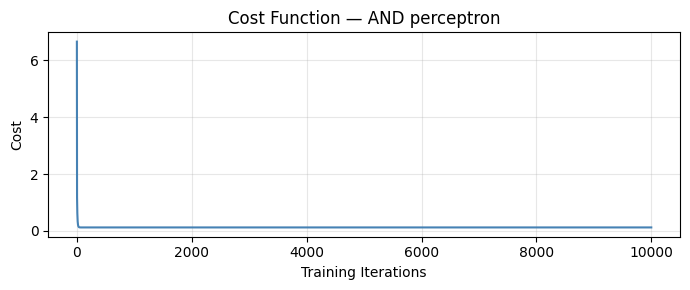

In [10]:
plt.figure(figsize=(7, 3))
plt.plot(range(num_iterations), cost_history, color='steelblue')
plt.title('Cost Function — AND perceptron')
plt.xlabel('Training Iterations')
plt.ylabel('Cost')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()